In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Trần Công Nhân - 6451071054")

# Đọc dữ liệu huấn luyện và kiểm thử
# Lưu ý: Nếu file không có sẵn header hoặc có khoảng trắng sau dấu phẩy, skipinitialspace=True sẽ tự làm sạch
train_df = pd.read_csv('adult.data.csv', skipinitialspace=True)
test_df = pd.read_csv('adult.test.csv', skipinitialspace=True)

print("Số lượng dữ liệu huấn luyện (train):", train_df.shape[0], "dòng,", train_df.shape[1], "cột")
print("Số lượng dữ liệu kiểm thử (test):", test_df.shape[0], "dòng,", test_df.shape[1], "cột")
display(train_df.head(5))

Trần Công Nhân - 6451071054
Số lượng dữ liệu huấn luyện (train): 32561 dòng, 15 cột
Số lượng dữ liệu kiểm thử (test): 16281 dòng, 14 cột


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [2]:
print("Trần Công Nhân - 6451071054")

# 1. Thay thế ký tự '?' bằng NaN và xóa các dòng chứa dữ liệu trống
train_df.replace('?', np.nan, inplace=True)
test_df.replace('?', np.nan, inplace=True)

train_df.dropna(inplace=True)
test_df.dropna(inplace=True)

# 2. Xóa cột 'fnlwgt' trong tập huấn luyện (và cả tập test nếu có)
if 'fnlwgt' in train_df.columns:
    train_df.drop(columns=['fnlwgt'], inplace=True)
if 'fnlwgt' in test_df.columns:
    test_df.drop(columns=['fnlwgt'], inplace=True)

# Làm sạch dấu chấm '.' ở cuối nhãn Income trong tập test (nếu có, vd: '>50K.' -> '>50K')
target_col = train_df.columns[-1] # Thường là 'Income' hoặc 'income'
train_df[target_col] = train_df[target_col].astype(str).str.replace('.', '', regex=False).str.strip()
test_df[target_col] = test_df[target_col].astype(str).str.replace('.', '', regex=False).str.strip()

# Lưu lại số lượng dòng của tập train sau khi làm sạch để lát tách lại
n_train = len(train_df)

# 3. Nối dữ liệu huấn luyện và kiểm thử thành 1 bảng duy nhất
full_df = pd.concat([train_df, test_df], axis=0, ignore_index=True)

print("Số dòng tập train sau tiền xử lý:", n_train)
print("Số dòng tập test sau tiền xử lý:", len(test_df))
print("Kích thước bảng dữ liệu sau khi nối:", full_df.shape)

Trần Công Nhân - 6451071054
Số dòng tập train sau tiền xử lý: 30162
Số dòng tập test sau tiền xử lý: 15060
Kích thước bảng dữ liệu sau khi nối: (45222, 14)


Trần Công Nhân - 6451071054


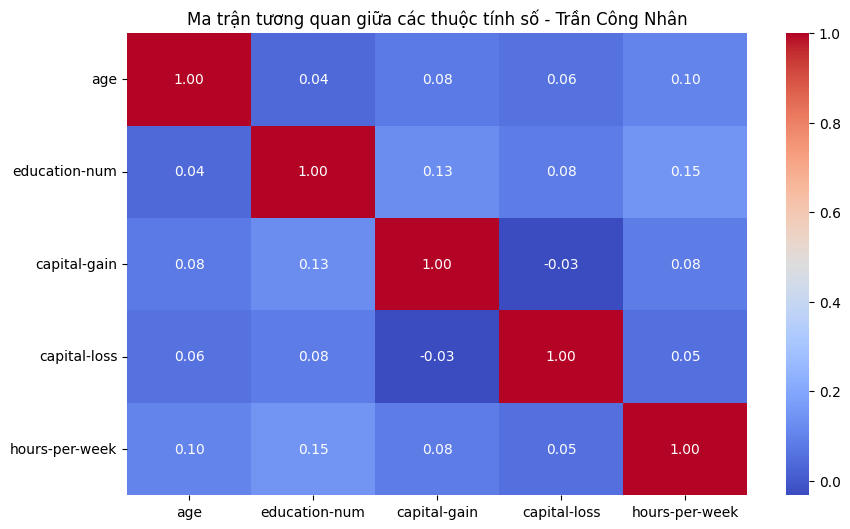

In [3]:
print("Trần Công Nhân - 6451071054")

# Vẽ ma trận tương quan (Heatmap) cho các thuộc tính dạng số
plt.figure(figsize=(10, 6))
numeric_cols = full_df.select_dtypes(include=[np.number])
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Ma trận tương quan giữa các thuộc tính số - Trần Công Nhân")
plt.show()

In [4]:
print("Trần Công Nhân - 6451071054")

# Tách thuộc tính quyết định (Income) ra trước khi One-Hot Encoding
X_raw = full_df.drop(columns=[target_col])
y_raw = full_df[target_col]

# Chuyển đổi các cột phân loại (object/category) bằng One-Hot Encoding (pd.get_dummies)
X_encoded = pd.get_dummies(X_raw, drop_first=False, dtype=int)

# Mã hóa nhãn mục tiêu: <=50K -> 0, >50K -> 1
y_encoded = y_raw.map({'<=50K': 0, '>50K': 1})

print("Kích thước dữ liệu đặc trưng sau khi mã hóa:", X_encoded.shape)
display(X_encoded.head(5))

Trần Công Nhân - 6451071054
Kích thước dữ liệu đặc trưng sau khi mã hóa: (45222, 103)


,age,education-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39,13,2174,0,40,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,50,13,0,0,13,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
2,38,9,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
3,53,7,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
4,28,13,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
print("Trần Công Nhân - 6451071054")

# Tách lại đúng theo vị trí n_train đã nối ở Câu 2
X_train = X_encoded.iloc[:n_train, :]
y_train = y_encoded.iloc[:n_train]

X_test = X_encoded.iloc[n_train:, :]
y_test = y_encoded.iloc[n_train:]

print("Kích thước X_train:", X_train.shape, "| y_train:", y_train.shape)
print("Kích thước X_test :", X_test.shape,  "| y_test :", y_test.shape)

Trần Công Nhân - 6451071054
Kích thước X_train: (30162, 103) | y_train: (30162,)
Kích thước X_test : (15060, 103) | y_test : (15060,)


Trần Công Nhân - 6451071054
Độ chính xác (Accuracy) của mô hình ID3: 0.8157 (81.57%)

Báo cáo phân lớp (ID3):
               precision    recall  f1-score   support

       <=50K       0.87      0.88      0.88     11360
        >50K       0.63      0.61      0.62      3700

    accuracy                           0.82     15060
   macro avg       0.75      0.75      0.75     15060
weighted avg       0.81      0.82      0.81     15060



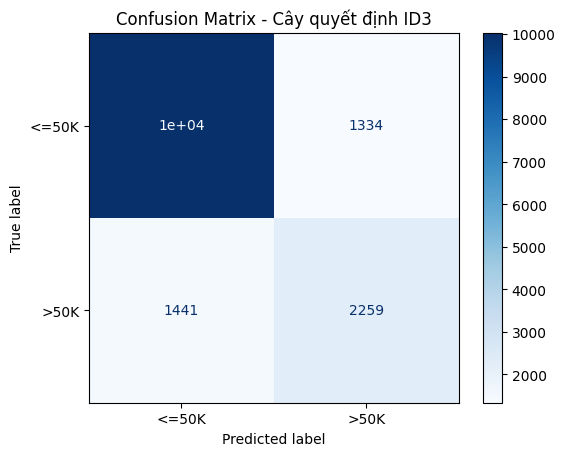

In [6]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

print("Trần Công Nhân - 6451071054")

# Khởi tạo và huấn luyện mô hình ID3 (sử dụng độ lợi thông tin - entropy)
id3_model = DecisionTreeClassifier(criterion='entropy', random_state=42)
id3_model.fit(X_train, y_train)

# Dự đoán trên tập kiểm thử
y_pred_id3 = id3_model.predict(X_test)

# Đánh giá kết quả
acc_id3 = accuracy_score(y_test, y_pred_id3)
print(f"Độ chính xác (Accuracy) của mô hình ID3: {acc_id3:.4f} ({acc_id3*100:.2f}%)")
print("\nBáo cáo phân lớp (ID3):\n", classification_report(y_test, y_pred_id3, target_names=['<=50K', '>50K']))

# Vẽ ma trận nhầm lẫn
cm_id3 = confusion_matrix(y_test, y_pred_id3)
disp_id3 = ConfusionMatrixDisplay(confusion_matrix=cm_id3, display_labels=['<=50K', '>50K'])
disp_id3.plot(cmap='Blues')
plt.title("Confusion Matrix - Cây quyết định ID3")
plt.show()

Trần Công Nhân - 6451071054
Độ chính xác (Accuracy) của mô hình CART: 0.8129 (81.29%)

Báo cáo phân lớp (CART):
               precision    recall  f1-score   support

       <=50K       0.87      0.88      0.88     11360
        >50K       0.62      0.60      0.61      3700

    accuracy                           0.81     15060
   macro avg       0.75      0.74      0.75     15060
weighted avg       0.81      0.81      0.81     15060



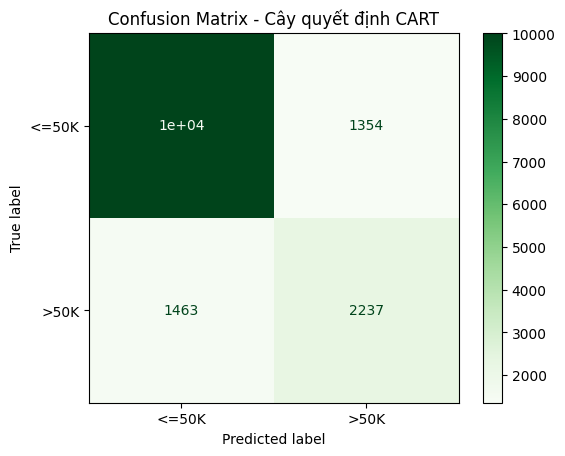

In [7]:
print("Trần Công Nhân - 6451071054")

# Khởi tạo và huấn luyện mô hình CART (sử dụng chỉ số Gini)
cart_model = DecisionTreeClassifier(criterion='gini', random_state=42)
cart_model.fit(X_train, y_train)

# Dự đoán trên tập kiểm thử
y_pred_cart = cart_model.predict(X_test)

# Đánh giá kết quả
acc_cart = accuracy_score(y_test, y_pred_cart)
print(f"Độ chính xác (Accuracy) của mô hình CART: {acc_cart:.4f} ({acc_cart*100:.2f}%)")
print("\nBáo cáo phân lớp (CART):\n", classification_report(y_test, y_pred_cart, target_names=['<=50K', '>50K']))

# Vẽ ma trận nhầm lẫn
cm_cart = confusion_matrix(y_test, y_pred_cart)
disp_cart = ConfusionMatrixDisplay(confusion_matrix=cm_cart, display_labels=['<=50K', '>50K'])
disp_cart.plot(cmap='Greens')
plt.title("Confusion Matrix - Cây quyết định CART")
plt.show()

Trần Công Nhân - 6451071054
Độ chính xác (Accuracy) của mô hình Naïve Bayes: 0.8029 (80.29%)

Báo cáo phân lớp (Naïve Bayes):
               precision    recall  f1-score   support

       <=50K       0.93      0.80      0.86     11360
        >50K       0.57      0.82      0.67      3700

    accuracy                           0.80     15060
   macro avg       0.75      0.81      0.76     15060
weighted avg       0.84      0.80      0.81     15060



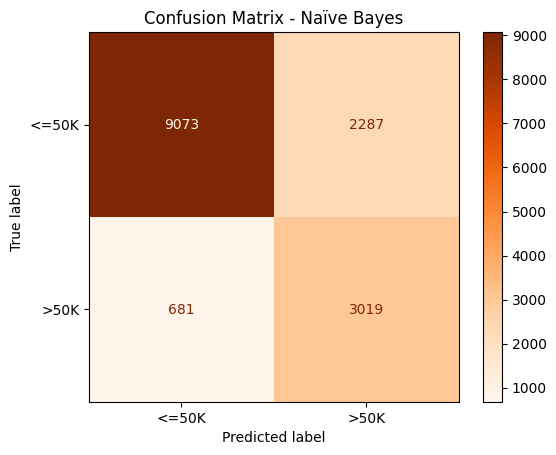

In [8]:
from sklearn.naive_bayes import GaussianNB

print("Trần Công Nhân - 6451071054")

# Khởi tạo và huấn luyện mô hình Naïve Bayes
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

# Dự đoán trên tập kiểm thử
y_pred_nb = nb_model.predict(X_test)

# Đánh giá kết quả
acc_nb = accuracy_score(y_test, y_pred_nb)
print(f"Độ chính xác (Accuracy) của mô hình Naïve Bayes: {acc_nb:.4f} ({acc_nb*100:.2f}%)")
print("\nBáo cáo phân lớp (Naïve Bayes):\n", classification_report(y_test, y_pred_nb, target_names=['<=50K', '>50K']))

# Vẽ ma trận nhầm lẫn
cm_nb = confusion_matrix(y_test, y_pred_nb)
disp_nb = ConfusionMatrixDisplay(confusion_matrix=cm_nb, display_labels=['<=50K', '>50K'])
disp_nb.plot(cmap='Oranges')
plt.title("Confusion Matrix - Naïve Bayes")
plt.show()

Trần Công Nhân - 6451071054


,Mô hình,Accuracy,Precision,Recall,F1-Score
0,ID3 (Entropy),0.815737,0.628723,0.610541,0.619498
1,CART (Gini),0.812948,0.622946,0.604595,0.613633
2,Naïve Bayes,0.802922,0.568979,0.815946,0.670442


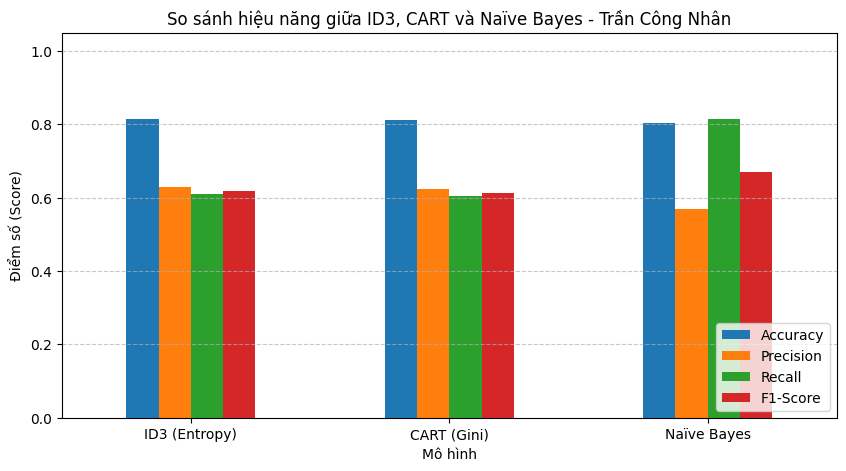

In [9]:
from sklearn.metrics import precision_score, recall_score, f1_score

print("Trần Công Nhân - 6451071054")

models = ['ID3 (Entropy)', 'CART (Gini)', 'Naïve Bayes']
preds = [y_pred_id3, y_pred_cart, y_pred_nb]

results = []
for name, y_p in zip(models, preds):
    results.append({
        'Mô hình': name,
        'Accuracy': accuracy_score(y_test, y_p),
        'Precision': precision_score(y_test, y_p),
        'Recall': recall_score(y_test, y_p),
        'F1-Score': f1_score(y_test, y_p)
    })

comparison_df = pd.DataFrame(results)
display(comparison_df)

# Vẽ biểu đồ cột so sánh
comparison_df.set_index('Mô hình').plot(kind='bar', figsize=(10, 5), rot=0)
plt.title("So sánh hiệu năng giữa ID3, CART và Naïve Bayes - Trần Công Nhân")
plt.ylabel("Điểm số (Score)")
plt.ylim(0, 1.05)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='lower right')
plt.show()

Trần Công Nhân - 6451071054


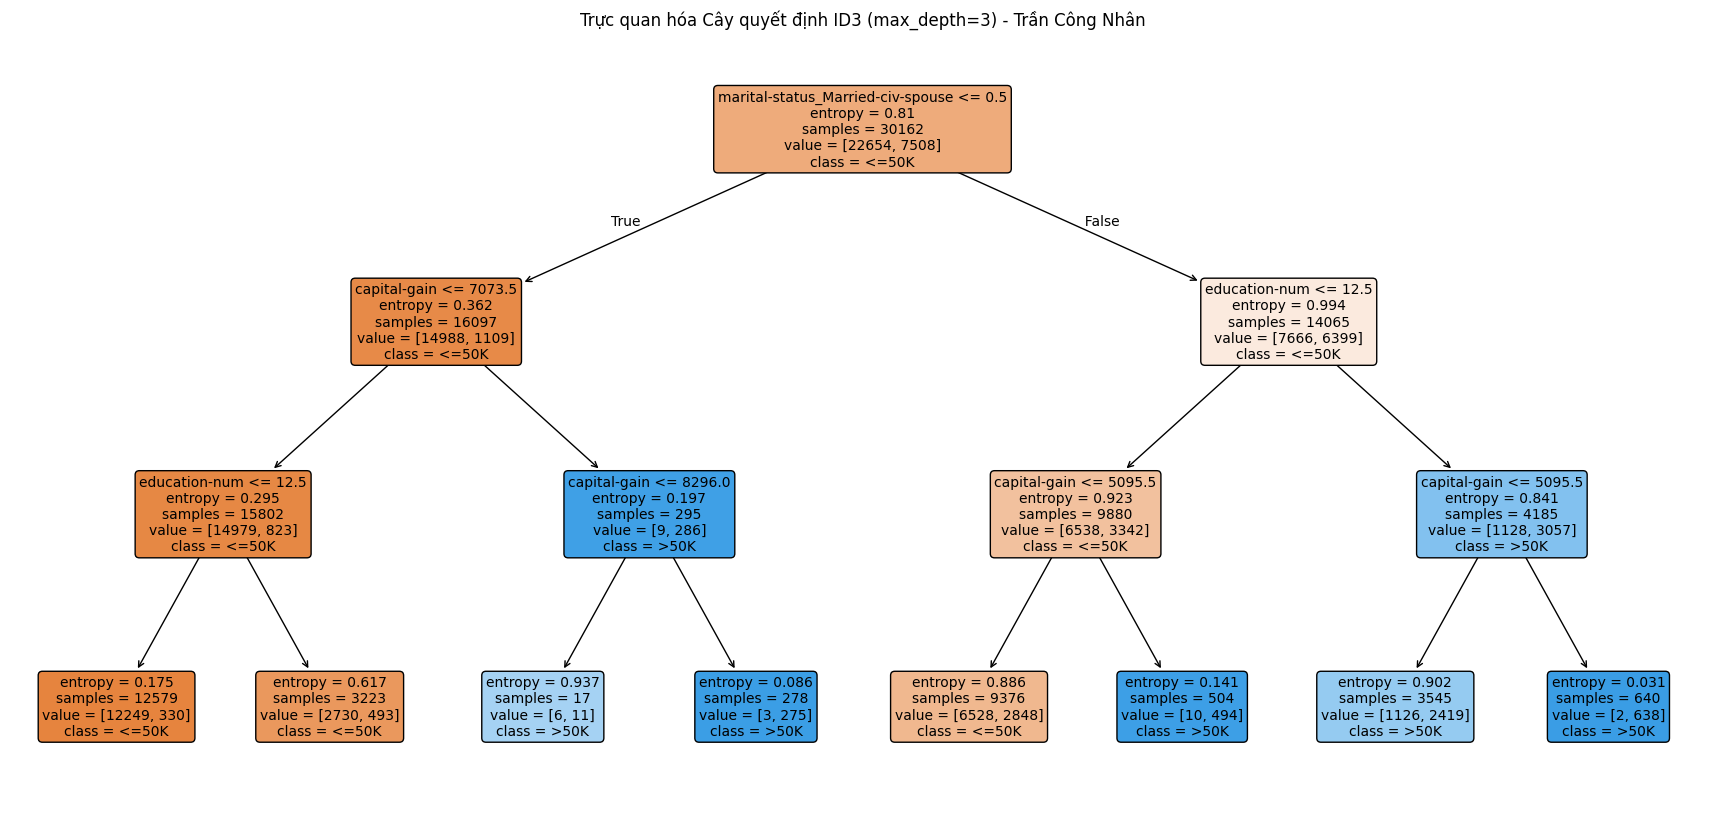

In [10]:
from sklearn.tree import plot_tree

print("Trần Công Nhân - 6451071054")

# Vẽ cây quyết định (giới hạn max_depth=3 để hiển thị trực quan, rõ chữ)
id3_vis = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
id3_vis.fit(X_train, y_train)

plt.figure(figsize=(22, 10))
plot_tree(
    id3_vis,
    feature_names=X_train.columns,
    class_names=['<=50K', '>50K'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Trực quan hóa Cây quyết định ID3 (max_depth=3) - Trần Công Nhân")
plt.show()